# Deep Learning / NLP Text Classifier with PyTorch
## SMS Spam Detection using TF-IDF + Deep Neural Network

### Project objective
Classify an SMS message as **Ham (normal)** or **Spam** using:
- NLP text preprocessing
- TF-IDF vectorization
- PyTorch deep neural network
- Batch Normalization
- Dropout
- Early Stopping
- Training/validation curves
- Test-set evaluation
- Confidence-based inference

**Dataset:** UCI SMS Spam Collection


## 1. Install the required libraries

If you already installed `requirements.txt`, you can skip the installation cell.

Run this in the terminal if needed:

```bash
pip install -r requirements.txt
```


In [11]:
# If needed, install packages from the notebook:
# %pip install pandas numpy scikit-learn matplotlib seaborn torch joblib


## 2. Import libraries

In [12]:
import os
import random
import urllib.request
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)


PyTorch version: 2.14.1+cpu


## 3. Set random seeds

In [13]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


## 4. Download the dataset

The notebook downloads the **SMS Spam Collection** from the official UCI Machine Learning Repository.

The dataset contains 5,574 SMS messages.


In [14]:
DATA_DIR = Path("../data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
ZIP_PATH = DATA_DIR / "sms_spam_collection.zip"
RAW_PATH = DATA_DIR / "SMSSpamCollection"
CSV_PATH = DATA_DIR / "sms_spam.csv"

if not RAW_PATH.exists():
    print("Downloading dataset from UCI...")
    urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)

    print("Download complete.")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

print("Raw dataset:", RAW_PATH)


Download complete.
Raw dataset: ..\data\SMSSpamCollection


## 5. Load and inspect the dataset

In [15]:
df = pd.read_csv(
    RAW_PATH,
    sep="\t",
    header=None,
    names=["label", "text"],
    encoding="utf-8"
)

df["label"] = df["label"].map({"ham": 0, "spam": 1})

# Remove missing values and duplicate messages
df = df.dropna(subset=["text", "label"]).drop_duplicates().reset_index(drop=True)

df.to_csv(CSV_PATH, index=False)

print("Dataset shape:", df.shape)
display(df.head(10))


Dataset shape: (5169, 2)


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."
5,1,FreeMsg Hey there darling it's been 3 week's n...
6,0,Even my brother is not like to speak with me. ...
7,0,As per your request 'Melle Melle (Oru Minnamin...
8,1,WINNER!! As a valued network customer you have...
9,1,Had your mobile 11 months or more? U R entitle...


In [16]:
print("Class counts:")
print(df["label"].value_counts())

print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))


Class counts:
label
0    4516
1     653
Name: count, dtype: int64

Class percentages:
label
0    87.37
1    12.63
Name: proportion, dtype: float64


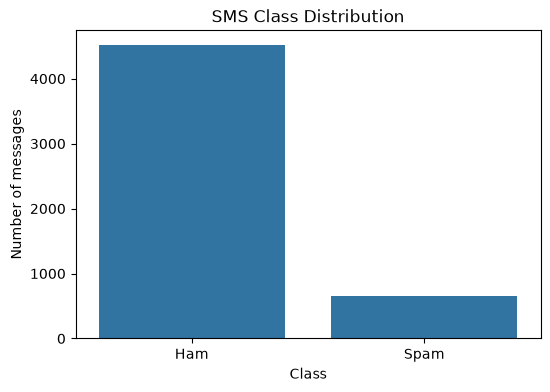

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df["label"].map({0: "Ham", 1: "Spam"}))
plt.title("SMS Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.show()


### What we are doing here
- `ham` messages are converted to **0**
- `spam` messages are converted to **1**
- Duplicate messages are removed.
- The class distribution is visualized before training.


## 6. Split the data into train, validation and test sets

In [18]:
X = df["text"].astype(str)
y = df["label"].astype(int)

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))


Training samples: 3618
Validation samples: 775
Test samples: 776


## 7. Convert text into numbers using TF-IDF

A neural network cannot directly understand raw text.

**TF-IDF** converts each SMS into a numerical vector based on how important words are in the document compared with the whole dataset.

Important: the vectorizer is fitted only on the **training data** to avoid data leakage.


In [19]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF validation shape:", X_val_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)


TF-IDF training shape: (3618, 5000)
TF-IDF validation shape: (775, 5000)
TF-IDF test shape: (776, 5000)


In [20]:
# Convert sparse TF-IDF matrices to float32 arrays for PyTorch
X_train_np = X_train_tfidf.toarray().astype(np.float32)
X_val_np = X_val_tfidf.toarray().astype(np.float32)
X_test_np = X_test_tfidf.toarray().astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Numeric input shape:", X_train_np.shape)


Numeric input shape: (3618, 5000)


## 8. Create PyTorch DataLoaders

In [21]:
train_dataset = TensorDataset(
    torch.tensor(X_train_np),
    torch.tensor(y_train_np).unsqueeze(1)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_np),
    torch.tensor(y_val_np).unsqueeze(1)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_np),
    torch.tensor(y_test_np).unsqueeze(1)
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("DataLoaders created successfully.")


DataLoaders created successfully.


## 9. Build the Deep Learning Neural Network

The network contains:
- Dense/Linear layer
- Batch Normalization
- ReLU activation
- Dropout
- Second Dense/Linear layer
- Batch Normalization
- ReLU
- Dropout
- Final output layer

This satisfies the assignment requirement for a **multi-layer neural network with Dropout and Batch Normalization**.


In [22]:
class SMSClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.35),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


input_dim = X_train_np.shape[1]
model = SMSClassifier(input_dim).to(device)

print(model)


SMSClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)


## 10. Define loss function and optimizer

The dataset has more normal messages than spam messages. We use a positive-class weight in `BCEWithLogitsLoss` so the model does not simply favor the majority class.

**Early stopping** will stop training if validation loss stops improving.


In [23]:
num_positive = y_train_np.sum()
num_negative = len(y_train_np) - num_positive
pos_weight = torch.tensor([num_negative / max(num_positive, 1)], dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

print("Positive-class weight:", float(pos_weight.item()))


Positive-class weight: 6.916849136352539


## 11. Training function

In [24]:
def binary_accuracy_from_logits(logits, targets):
    probs = torch.sigmoid(logits)
    preds = (probs >= 0.5).float()
    return (preds == targets).float().mean().item()


def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_items = 0

    for features, targets in loader:
        features = features.to(device)
        targets = targets.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            logits = model(features)
            loss = criterion(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        total_correct += (predictions == targets).sum().item()
        total_items += batch_size

    return total_loss / total_items, total_correct / total_items


## 12. Train the model with Early Stopping

In [25]:
EPOCHS = 20
PATIENCE = 4

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
patience_counter = 0
best_state = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, optimizer=optimizer
    )

    val_loss, val_acc = run_epoch(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

print("Training completed.")


Epoch 01/20 | Train Loss: 0.5235 | Train Acc: 0.8203 | Val Loss: 0.7047 | Val Acc: 0.9742
Epoch 02/20 | Train Loss: 0.1404 | Train Acc: 0.9873 | Val Loss: 0.2016 | Val Acc: 0.9755
Epoch 03/20 | Train Loss: 0.0684 | Train Acc: 0.9959 | Val Loss: 0.1975 | Val Acc: 0.9768
Epoch 04/20 | Train Loss: 0.0388 | Train Acc: 0.9989 | Val Loss: 0.2031 | Val Acc: 0.9819
Epoch 05/20 | Train Loss: 0.0264 | Train Acc: 0.9992 | Val Loss: 0.2159 | Val Acc: 0.9806
Epoch 06/20 | Train Loss: 0.0178 | Train Acc: 0.9997 | Val Loss: 0.2475 | Val Acc: 0.9794
Epoch 07/20 | Train Loss: 0.0129 | Train Acc: 0.9997 | Val Loss: 0.2413 | Val Acc: 0.9768
Early stopping triggered.
Training completed.


## 13. Plot training and validation curves

These graphs are required as proof of training convergence.


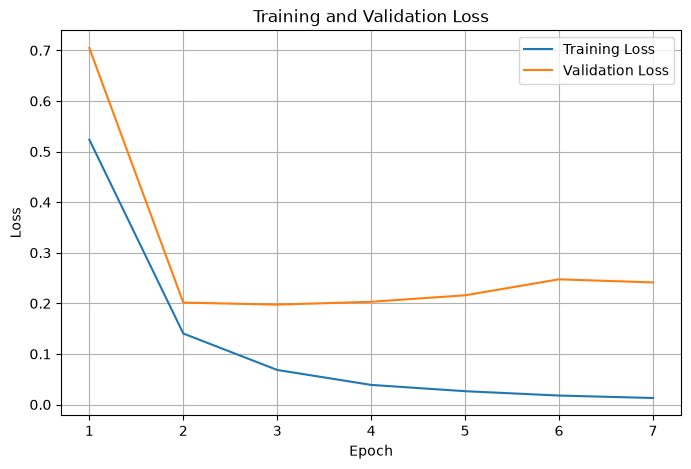

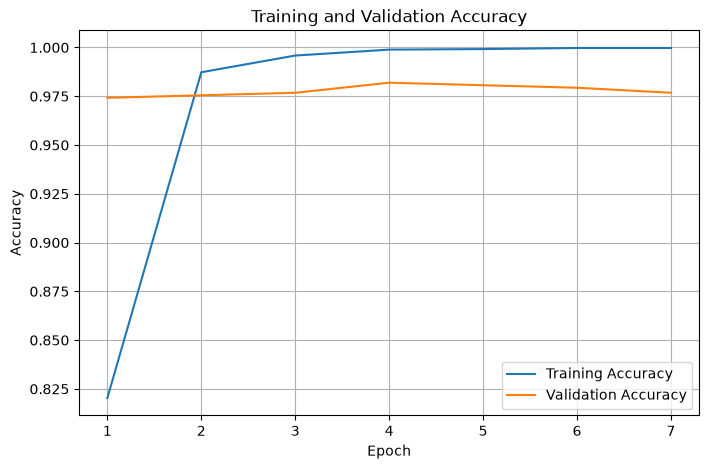

In [26]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history["train_loss"], label="Training Loss")
plt.plot(epochs_ran, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history["train_acc"], label="Training Accuracy")
plt.plot(epochs_ran, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## 14. Evaluate on unseen test data

In [27]:
model.eval()

all_probs = []
all_targets = []

with torch.no_grad():
    for features, targets in test_loader:
        features = features.to(device)

        logits = model(features)
        probs = torch.sigmoid(logits).cpu().numpy().ravel()

        all_probs.extend(probs.tolist())
        all_targets.extend(targets.numpy().ravel().tolist())

all_probs = np.array(all_probs)
all_targets = np.array(all_targets).astype(int)

all_preds = (all_probs >= 0.5).astype(int)

accuracy = accuracy_score(all_targets, all_preds)
precision = precision_score(all_targets, all_preds, zero_division=0)
recall = recall_score(all_targets, all_preds, zero_division=0)
f1 = f1_score(all_targets, all_preds, zero_division=0)

print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall   : {recall:.4f}")
print(f"Test F1-score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_targets,
        all_preds,
        target_names=["Ham", "Spam"],
        digits=4,
        zero_division=0
    )
)


Test Accuracy : 0.9820
Test Precision: 0.9038
Test Recall   : 0.9592
Test F1-score : 0.9307

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9940    0.9853    0.9896       678
        Spam     0.9038    0.9592    0.9307        98

    accuracy                         0.9820       776
   macro avg     0.9489    0.9722    0.9602       776
weighted avg     0.9827    0.9820    0.9822       776



## 15. Confusion Matrix

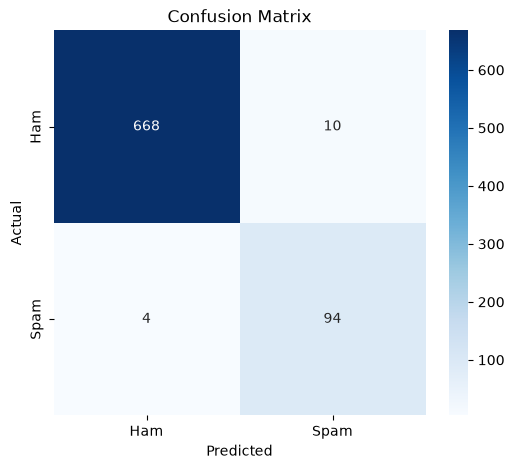

In [28]:
cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## 16. Test the model on unseen SMS messages

The model returns:
- predicted class
- probability/confidence for Spam
- probability/confidence for Ham


In [29]:
def predict_message(message, threshold=0.5):
    vector = vectorizer.transform([message]).toarray().astype(np.float32)
    tensor = torch.tensor(vector).to(device)

    model.eval()
    with torch.no_grad():
        logit = model(tensor)
        spam_probability = torch.sigmoid(logit).item()

    if spam_probability >= threshold:
        label = "SPAM"
        confidence = spam_probability
    else:
        label = "HAM"
        confidence = 1 - spam_probability

    return label, confidence, spam_probability


sample_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward.",
    "Hi, are we still meeting at the library today?",
    "URGENT! You have won a cash prize. Text WIN to claim now.",
    "Can you send me the assignment notes when you are free?"
]

for message in sample_messages:
    label, confidence, spam_probability = predict_message(message)
    print("Message:", message)
    print(f"Prediction: {label}")
    print(f"Confidence: {confidence * 100:.2f}%")
    print(f"Spam probability: {spam_probability * 100:.2f}%")
    print("-" * 70)


Message: Congratulations! You have won a free prize. Call now to claim your reward.
Prediction: SPAM
Confidence: 99.99%
Spam probability: 99.99%
----------------------------------------------------------------------
Message: Hi, are we still meeting at the library today?
Prediction: HAM
Confidence: 98.68%
Spam probability: 1.32%
----------------------------------------------------------------------
Message: URGENT! You have won a cash prize. Text WIN to claim now.
Prediction: SPAM
Confidence: 100.00%
Spam probability: 100.00%
----------------------------------------------------------------------
Message: Can you send me the assignment notes when you are free?
Prediction: SPAM
Confidence: 68.24%
Spam probability: 68.24%
----------------------------------------------------------------------


### Example of how to explain the output

If the output is:

`Prediction: SPAM`  
`Confidence: 98.50%`

you can say:

> The model classified the unseen SMS as spam with 98.50% confidence. The prediction was produced after converting the message into TF-IDF features and passing those features through the trained PyTorch neural network.


## 17. Save the trained model and TF-IDF vectorizer

In [30]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": input_dim,
        "threshold": 0.5
    },
    MODEL_DIR / "sms_spam_classifier.pth"
)

joblib.dump(vectorizer, MODEL_DIR / "tfidf_vectorizer.joblib")

print("Saved:")
print(MODEL_DIR / "sms_spam_classifier.pth")
print(MODEL_DIR / "tfidf_vectorizer.joblib")


Saved:
..\models\sms_spam_classifier.pth
..\models\tfidf_vectorizer.joblib


## 18. Final project conclusion

### Conclusion
This project successfully builds a deep-learning NLP pipeline for SMS spam detection. TF-IDF is used to convert text into numerical features, and a multi-layer PyTorch neural network performs binary classification. Batch Normalization and Dropout improve the training process, while Early Stopping helps control overfitting. The final model is evaluated on unseen test data using accuracy, precision, recall, F1-score and a confusion matrix. The model can also classify new SMS messages and report prediction confidence.

### Assignment requirements covered

| Requirement | Implementation |
|---|---|
| Text classification | SMS Spam / Ham |
| Dataset | UCI SMS Spam Collection |
| Tokenize/vectorize | TF-IDF |
| Deep neural network | PyTorch multi-layer network |
| Dropout | Yes |
| Batch Normalization | Yes |
| Early stopping | Yes |
| Training curves | Loss + Accuracy |
| Unseen samples | Yes |
| Classification confidence | Yes |
| Expected proof | Jupyter Notebook with outputs |

**Important:** use your own final accuracy, precision, recall and F1-score from the notebook in your report.
